In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, LinearRegression

In [ ]:
np.random.seed(42)

1.	Сгенерируем датасет:

In [ ]:
X, y, weights = make_regression(
    n_samples=50,
    n_features=3,
    n_informative=3,
    noise=20,
    random_state=42,
    coef=True
)

print(f"Размер матрицы признаков X: {X.shape}")
print(f"Размер вектора целевых значений y: {y.shape}")
print(f"Размер вектора весов w: {weights.shape}")

Размер матрицы признаков X: (50, 3)
Размер вектора целевых значений y: (50,)
Размер вектора весов w: (3,)


In [ ]:
display(X, y)

array([[ 0.29612028,  0.00511346,  0.26105527],
       [ 0.09707755, -0.70205309,  0.96864499],
       [-0.02651388,  2.46324211,  0.06023021],
       [-0.47917424, -1.10633497, -0.18565898],
       [ 1.57921282, -0.46947439,  0.76743473],
       [-0.54438272, -1.15099358,  0.11092259],
       [-0.38508228,  0.61167629, -0.676922  ],
       [-1.06230371, -0.91942423,  0.47359243],
       [ 0.54256004, -0.46572975, -0.46341769],
       [-0.99053633,  0.09965137, -0.56629773],
       [ 0.25755039, -1.91877122, -0.07444592],
       [-0.50347565,  0.06856297, -1.55066343],
       [ 0.25988279, -1.23695071,  0.78182287],
       [ 0.32875111,  0.51326743, -0.5297602 ],
       [-0.19236096, -0.03471177,  0.30154734],
       [-1.16867804,  0.75193303,  1.14282281],
       [ 0.24196227, -1.72491783, -1.91328024],
       [-0.60170661, -0.01349722,  1.85227818],
       [-0.23458713, -0.42064532, -1.41537074],
       [-0.56228753,  0.31424733, -1.01283112],
       [ 0.37569802, -0.29169375, -0.600

array([  37.90654551,   36.59719355,  150.23382937, -103.82855274,
        173.29510175, -128.56188955,  -63.11567929,  -95.18268004,
        -42.24946959, -121.01630032, -124.67102598, -177.37186862,
        -14.57000828,   18.05631898,   18.42643912,   35.58017219,
       -217.50613859,  105.61105197, -142.65697414,  -82.1901992 ,
        -54.85090434,  101.91579921, -113.60348307, -180.2296082 ,
        -29.72351924,   23.76922158,   56.75841668,  127.77987728,
         55.08713813,    8.22650066, -138.80149497,  118.76055691,
        133.20532578, -146.01995556,  149.78177695,  -82.69406974,
        104.86759336,  -28.99266442, -125.32523713,   79.38936267,
         56.24580908,  187.30744271,  -81.90238455, -211.08589745,
         71.57878534,  -77.47937829,  -82.41301156,   59.81063209,
         97.30417755,  -51.23986061])

In [ ]:
weights

array([88.70864243, 64.20316462, 77.98755459])

Выполним масштабирование данных, разобъём данные на train и test:

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[ 0.46059057,  0.09051597,  0.37187464],
       [ 0.19297154, -0.58716557,  1.07875215],
       [ 0.0267991 ,  2.44615401,  0.17125171],
       [-0.58181657, -0.97459109, -0.07438998],
       [ 2.18574764, -0.36428414,  0.87774441],
       [-0.66949137, -1.01738768,  0.22189307],
       [-0.45530706,  0.67178843, -0.56515854],
       [-1.36585194, -0.79547352,  0.58419787],
       [ 0.79193635, -0.36069563, -0.35186913],
       [-1.2693585 ,  0.18111216, -0.45464561],
       [ 0.40873218, -1.75315316,  0.03671114],
       [-0.61449056,  0.15131999, -1.43802052],
       [ 0.41186816, -1.09976086,  0.89211807],
       [ 0.50446372,  0.57748269, -0.41814486],
       [-0.19618737,  0.05235124,  0.41232595],
       [-1.50887547,  0.80619723,  1.25275466],
       [ 0.38777347, -1.56738241, -1.80027235],
       [-0.74656509,  0.07268125,  1.96149594],
       [-0.25296174, -0.31749098, -1.30286401],
       [-0.69356493,  0.38676064, -0.90072955],
       [ 0.56758527, -0.19391599, -0.488

In [ ]:
X_scaled = np.column_stack([X_scaled, np.ones((50))])
X_scaled

array([[ 0.46059057,  0.09051597,  0.37187464,  1.        ],
       [ 0.19297154, -0.58716557,  1.07875215,  1.        ],
       [ 0.0267991 ,  2.44615401,  0.17125171,  1.        ],
       [-0.58181657, -0.97459109, -0.07438998,  1.        ],
       [ 2.18574764, -0.36428414,  0.87774441,  1.        ],
       [-0.66949137, -1.01738768,  0.22189307,  1.        ],
       [-0.45530706,  0.67178843, -0.56515854,  1.        ],
       [-1.36585194, -0.79547352,  0.58419787,  1.        ],
       [ 0.79193635, -0.36069563, -0.35186913,  1.        ],
       [-1.2693585 ,  0.18111216, -0.45464561,  1.        ],
       [ 0.40873218, -1.75315316,  0.03671114,  1.        ],
       [-0.61449056,  0.15131999, -1.43802052,  1.        ],
       [ 0.41186816, -1.09976086,  0.89211807,  1.        ],
       [ 0.50446372,  0.57748269, -0.41814486,  1.        ],
       [-0.19618737,  0.05235124,  0.41232595,  1.        ],
       [-1.50887547,  0.80619723,  1.25275466,  1.        ],
       [ 0.38777347, -1.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print(f"Обучающая выборка: {X_train.shape}")
print(f"Тестовая выборка:  {X_test.shape}")

Обучающая выборка: (40, 4)
Тестовая выборка:  (10, 4)


Функции MSE и градиента:

In [ ]:
def mse(X, y, w):
    n = X.shape[0]
    residuals = X @ w - y
    return (1 / n) * np.dot(residuals, residuals)


def gradient(X, y, w):
    n = X.shape[0]
    return (2 / n) * X.T @ (X @ w - y)

2.	Напишем самостоятельно функцию градиентного спуска.

In [ ]:
def gradient_descent(X, y, lr, max_iter, eps):
    n_features = X.shape[1]
    w = np.zeros(n_features)      # инициализация начальных весов нулями
    history = []

    for i in range(max_iter):     # цикл по количеству итераций
        grad = gradient(X, y, w)
        w_new = w - lr * grad     # расчёт новых весов

        history.append(mse(X, y, w_new))

        if np.linalg.norm(w_new - w) < eps:   # критерий останова
            print(f"Сошёлся за {i+1} итераций\n")
            w = w_new
            break
        w = w_new
    else:
        print(f"Достигнут лимит {max_iter} итераций\n")

    return w, history

In [ ]:
w_gd, gd_history = gradient_descent(X_train, y_train, lr=0.05, max_iter=10000, eps=1e-6)

print(f"\nФинальные веса : {np.round(w_gd, 4)}")
print(f"MSE на обучении: {mse(X_train, y_train, w_gd):.4f}")
print(f"MSE на тесте:    {mse(X_test,  y_test,  w_gd):.4f}")

Сошёлся за 219 итераций


Финальные веса : [ 63.5184  67.7514  81.17   -15.7691]
MSE на обучении: 306.1120
MSE на тесте:    354.1780


3.	Поэкспериментируем со скоростью обучения.

In [ ]:
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.5]

for lr in learning_rates:
    print(f"При скорости обучения {lr}:")
    w, hist = gradient_descent(X_train, y_train, lr=lr, max_iter=10000, eps=1e-6)



При скорости обучения 0.001:
Сошёлся за 8459 итераций

При скорости обучения 0.01:
Сошёлся за 1005 итераций

При скорости обучения 0.05:
Сошёлся за 219 итераций

При скорости обучения 0.1:
Сошёлся за 111 итераций

При скорости обучения 0.5:
Сошёлся за 17 итераций



Выводы:
- При слишком малом lr (0.001) сходимость медленная — требуется много итераций.
- Оптимальный диапазон (0.05–0.1) даёт быстрое и устойчивое снижение ошибки.
- При слишком большом lr (0.5) возможна расходимость или медленная сходимость
  из-за «перепрыгивания» минимума.

4.	Добавим в функцию выбор случайного объекта на каждой итерации для нахождения весов, чтобы сделать функцию стохастического градиентного спуска.

In [ ]:
def stochastic_gradient_descent(X, y, lr, max_iter, eps):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    history = []

    for i in range(max_iter):
        idx = np.random.randint(0, n_samples)
        xi  = X[idx:idx+1]
        yi  = y[idx:idx+1]

        grad  = gradient(xi, yi, w)
        w_new = w - lr * grad

        history.append(mse(X, y, w_new))

        if np.linalg.norm(w_new - w) < eps:
            print(f"Сошёлся за {i+1} итераций")
            w = w_new
            break
        w = w_new
    else:
        print(f"Достигнут лимит {max_iter} итераций")

    return w, history

In [ ]:
w_sgd, sgd_history = stochastic_gradient_descent(
    X_train, y_train, lr=0.01, max_iter=10000, eps=1e-6
)

print(f"\nФинальные веса (SGD): {np.round(w_sgd, 4)}")
print(f"MSE на обучении: {mse(X_train, y_train, w_sgd):.4f}")
print(f"MSE на тесте:    {mse(X_test,  y_test,  w_sgd):.4f}")

Достигнут лимит 10000 итераций

Финальные веса (SGD): [ 62.569   65.8171  81.3062 -18.5017]
MSE на обучении: 316.8755
MSE на тесте:    463.0705


5.	Обучим линейную модель при помощи градиентного и стохастического градиентного спуска. Нанесём среднеквадратичную ошибку для обоих методов на один график

Сошёлся за 314 итераций

Достигнут лимит 500 итераций


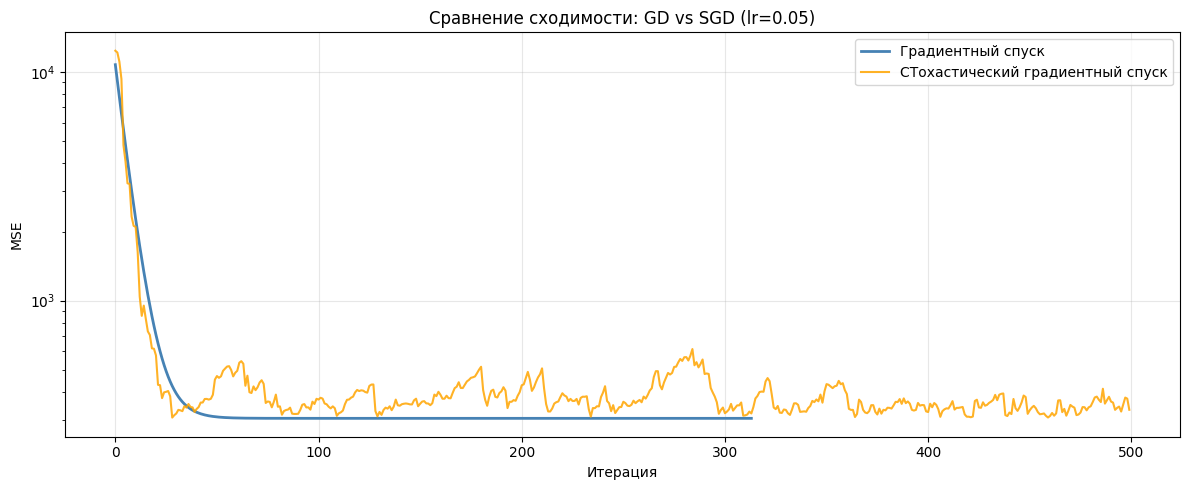


Градиентный спуск — итоговый MSE на тесте: 354.1778
Стохастический градиентный спуск — итоговый MSE на тесте: 409.4719


In [ ]:
MAX_ITER = 500
LR = 0.05

w_gd,  gd_hist  = gradient_descent(
    X_train, y_train, lr=LR, max_iter=MAX_ITER, eps=1e-9
)
w_sgd, sgd_hist = stochastic_gradient_descent(
    X_train, y_train, lr=LR, max_iter=MAX_ITER, eps=1e-9
)

plt.figure(figsize=(12, 5))
plt.plot(gd_hist,  label='Градиентный спуск',  color='steelblue', linewidth=2)
plt.plot(sgd_hist, label='СТохастический градиентный спуск',       color='orange',    linewidth=1.5, alpha=0.85)
plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.title('Сравнение сходимости: GD vs SGD (lr=0.05)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nГрадиентный спуск — итоговый MSE на тесте: {mse(X_test, y_test, w_gd):.4f}")
print(f"Стохастический градиентный спуск — итоговый MSE на тесте: {mse(X_test, y_test, w_sgd):.4f}")

- GD даёт гладкую, монотонно убывающую кривую ошибки — каждый шаг
  гарантированно движется в сторону минимума.
- SGD сходится быстрее в начале (по числу итераций), но кривая шумная:
  случайный выбор одного объекта вносит дисперсию в оценку градиента.
- При достаточно большом числе итераций оба метода приходят к близким
  значениям ошибки.

6.	Реализуем L2 регуляризацию, возьмём 20 коэффициентов регуляризации (от 0,001 до 1000)

In [ ]:
alphas = np.logspace(-3, 3, 20)
weights_matrix = []
models=[]

alphas

array([1.00000000e-03, 2.06913808e-03, 4.28133240e-03, 8.85866790e-03,
       1.83298071e-02, 3.79269019e-02, 7.84759970e-02, 1.62377674e-01,
       3.35981829e-01, 6.95192796e-01, 1.43844989e+00, 2.97635144e+00,
       6.15848211e+00, 1.27427499e+01, 2.63665090e+01, 5.45559478e+01,
       1.12883789e+02, 2.33572147e+02, 4.83293024e+02, 1.00000000e+03])

In [ ]:
for alpha in alphas:
    model = Ridge(alpha=alpha).fit(X_train, y_train)
    weights_matrix.append(model.coef_)
    models.append(model)

weights_matrix = np.array(weights_matrix)

In [ ]:
import pandas as pd
rows = []
for i, m in enumerate(models):
    rows.append({
        'alpha': alphas[i],
        'train_r2': m.score(X_train, y_train),
        'test_r2': m.score(X_test, y_test)
    })


scores = pd.DataFrame(rows)
scores

,alpha,train_r2,test_r2
0,0.001000,0.974816,0.953489
1,0.002069,0.974816,0.953485
2,0.004281,0.974816,0.953477
3,0.008859,0.974816,0.953461
4,0.018330,0.974816,0.953426
5,0.037927,0.974815,0.953354
6,0.078476,0.974810,0.953203
7,0.162378,0.974789,0.952879
8,0.335982,0.974703,0.952164
9,0.695193,0.974344,0.950495


Покажем на графике как изменяются веса в зависимости от коэффициента регуляризации.

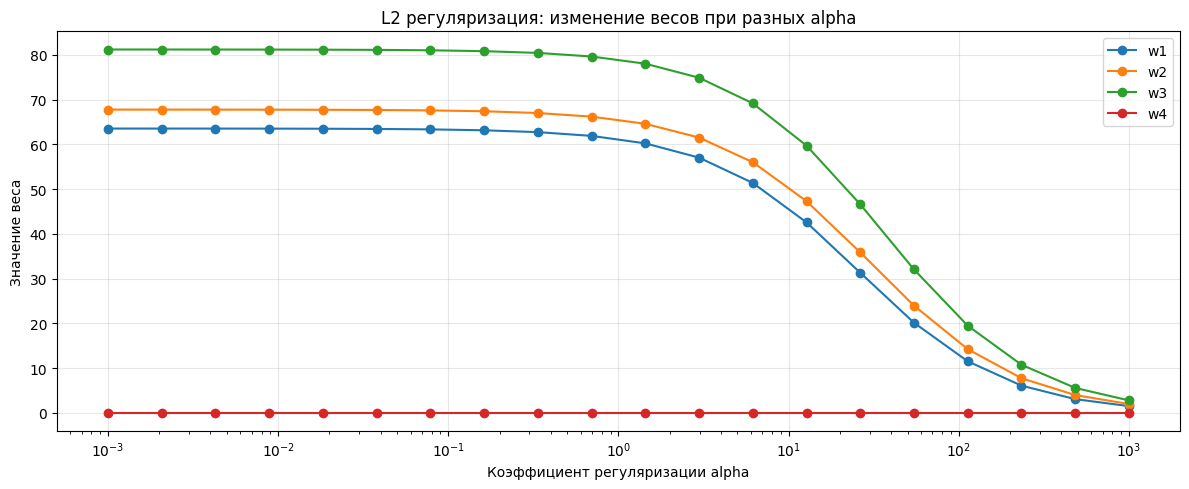

In [ ]:
plt.figure(figsize=(12, 5))
for i in range(weights_matrix.shape[1]):
    plt.plot(alphas, weights_matrix[:, i], marker='o', label=f'w{i+1}')

plt.xscale('log')
plt.xlabel('Коэффициент регуляризации alpha')
plt.ylabel('Значение веса')
plt.title('L2 регуляризация: изменение весов при разных alpha')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()